# Training MobileNetV2 Uang Rupiah TE 2016, TE 2022, dan Area Kosong

Notebook ini melatih **8 kelas**:

```text
1000
2000
5000
10000
20000
50000
100000
kosong
```

Kelas `kosong` digunakan ketika area pemindaian tidak berisi objek.

Struktur arsip dataset yang diharapkan:

```text
dataset_raw/
├── 1000/
├── 2000/
├── 5000/
├── 10000/
├── 20000/
├── 50000/
├── 100000/
└── kosong/
```

TE 2016 dan TE 2022 tetap digabung berdasarkan nominal karena keluaran model adalah nominal uang, bukan tahun emisi.


## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Instalasi dan import library

In [ ]:
%pip -q install py7zr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.2/72.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 495.6/495.6 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.6/100.6 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.3/144.3 kB 16.3 MB/s eta 0:00:00


In [ ]:
import shutil
import random
import tarfile
import zipfile
from pathlib import Path

import py7zr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Folder penyimpanan gambar dan tabel untuk laporan.
REPORT_DIR = Path("/content/report_figures")
REPORT_DIR.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Cari dan ekstrak dataset

In [ ]:
# ============================================================
# PATH DATASET DI GOOGLE DRIVE
# ============================================================

ARCHIVE_PATH = Path(
    "/content/drive/MyDrive/tugas akhir/dataset_1400.7z"
)

# Pastikan file dataset tersedia
if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan di:\n{ARCHIVE_PATH}\n\n"
        "Pastikan Google Drive sudah di-mount, "
        "nama folder benar, dan file dataset_1400.7z tersedia."
    )

print("Dataset ditemukan di:", ARCHIVE_PATH)


# ============================================================
# FOLDER EKSTRAKSI DATASET
# ============================================================

EXTRACT_DIR = Path("/content/dataset_extracted")

# Hapus hasil ekstraksi lama agar tidak tercampur
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)

EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

archive_name = ARCHIVE_PATH.name.lower()


# ============================================================
# EKSTRAK DATASET
# ============================================================

if archive_name.endswith(".7z"):
    with py7zr.SevenZipFile(
        ARCHIVE_PATH,
        mode="r"
    ) as archive:
        archive.extractall(EXTRACT_DIR)

elif archive_name.endswith(".tar.gz") or archive_name.endswith(".tgz"):
    with tarfile.open(
        ARCHIVE_PATH,
        mode="r:gz"
    ) as archive:
        archive.extractall(EXTRACT_DIR)

elif archive_name.endswith(".zip"):
    with zipfile.ZipFile(
        ARCHIVE_PATH,
        mode="r"
    ) as archive:
        archive.extractall(EXTRACT_DIR)

else:
    raise ValueError(
        "Format arsip belum didukung. "
        "Gunakan .7z, .tar.gz, .tgz, atau .zip."
    )

print("Dataset berhasil diekstrak ke:", EXTRACT_DIR)


# ============================================================
# DAFTAR KELAS
# ============================================================

CLASS_NAMES = [
    "1000",
    "2000",
    "5000",
    "10000",
    "20000",
    "50000",
    "100000",
    "kosong",
]

DISPLAY_NAMES = {
    "1000": "Rp1.000",
    "2000": "Rp2.000",
    "5000": "Rp5.000",
    "10000": "Rp10.000",
    "20000": "Rp20.000",
    "50000": "Rp50.000",
    "100000": "Rp100.000",
    "kosong": "Kosong",
}


# ============================================================
# CARI FOLDER UTAMA DATASET
# ============================================================

# Kondisi 1:
# Arsip berisi folder bernama dataset_raw
possible_dirs = [
    folder
    for folder in EXTRACT_DIR.rglob("dataset_raw")
    if folder.is_dir()
]

if possible_dirs:
    RAW_DIR = possible_dirs[0]

# Kondisi 2:
# Arsip langsung berisi folder kelas
elif all(
    (EXTRACT_DIR / class_name).is_dir()
    for class_name in CLASS_NAMES
):
    RAW_DIR = EXTRACT_DIR

# Kondisi 3:
# Folder kelas berada di dalam folder lain
else:
    candidate_roots = [
        folder
        for folder in EXTRACT_DIR.rglob("*")
        if folder.is_dir()
        and all(
            (folder / class_name).is_dir()
            for class_name in CLASS_NAMES
        )
    ]

    if not candidate_roots:
        folder_ditemukan = [
            str(folder.relative_to(EXTRACT_DIR))
            for folder in EXTRACT_DIR.rglob("*")
            if folder.is_dir()
        ]

        raise FileNotFoundError(
            "Struktur dataset tidak ditemukan.\n\n"
            "Pastikan arsip memiliki folder berikut:\n"
            "1000, 2000, 5000, 10000, 20000, "
            "50000, 100000, dan kosong.\n\n"
            "Folder yang ditemukan setelah ekstraksi:\n"
            + "\n".join(folder_ditemukan[:30])
        )

    RAW_DIR = candidate_roots[0]

print("RAW_DIR:", RAW_DIR)


# ============================================================
# VALIDASI JUMLAH GAMBAR SETIAP KELAS
# ============================================================

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
}

class_counts = {}
missing_classes = []

for class_name in CLASS_NAMES:
    class_dir = RAW_DIR / class_name

    if not class_dir.is_dir():
        missing_classes.append(class_name)
        class_counts[class_name] = 0
        continue

    files = [
        file_path
        for file_path in class_dir.iterdir()
        if file_path.is_file()
        and file_path.suffix.lower() in VALID_EXTENSIONS
    ]

    class_counts[class_name] = len(files)


# Periksa folder kelas yang tidak ditemukan
if missing_classes:
    raise FileNotFoundError(
        "Folder kelas belum lengkap: "
        + ", ".join(missing_classes)
    )


# Tampilkan jumlah gambar
print("\nJumlah gambar per kelas:")
print("-" * 35)

for class_name in CLASS_NAMES:
    print(
        f"{DISPLAY_NAMES[class_name]:>10}: "
        f"{class_counts[class_name]} gambar"
    )

total_images = sum(class_counts.values())

print("-" * 35)
print(f"{'Total':>10}: {total_images} gambar")


# Pastikan setiap kelas mempunyai gambar
empty_classes = [
    class_name
    for class_name, count in class_counts.items()
    if count == 0
]

if empty_classes:
    raise ValueError(
        "Terdapat kelas tanpa gambar: "
        + ", ".join(empty_classes)
    )

print(
    "\nDataset sudah lengkap dan siap "
    "digunakan untuk proses training."
)

Dataset ditemukan di: /content/drive/MyDrive/tugas akhir/dataset_1400.7z
Dataset berhasil diekstrak ke: /content/dataset_extracted
RAW_DIR: /content/dataset_extracted/dataset_raw

Jumlah gambar per kelas:
-----------------------------------
   Rp1.000: 200 gambar
   Rp2.000: 200 gambar
   Rp5.000: 200 gambar
  Rp10.000: 200 gambar
  Rp20.000: 200 gambar
  Rp50.000: 200 gambar
 Rp100.000: 200 gambar
    Kosong: 120 gambar
-----------------------------------
     Total: 1520 gambar

Dataset sudah lengkap dan siap digunakan untuk proses training.


## 4. Grafik distribusi dataset

Grafik ini dapat digunakan pada laporan untuk menunjukkan jumlah citra pada setiap kelas sebelum pembagian data.


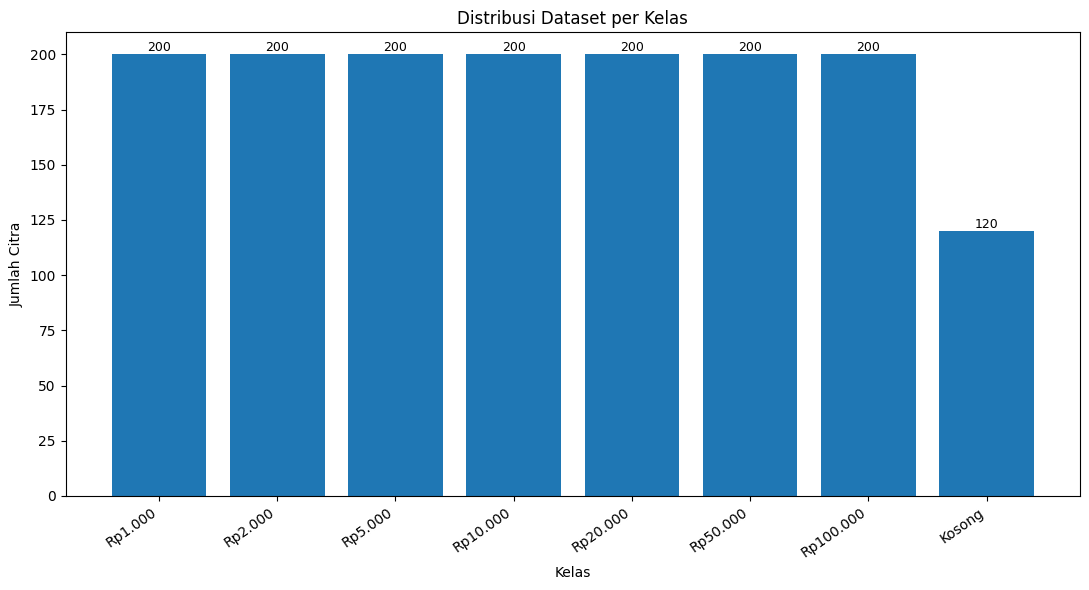

In [ ]:
labels_display = [
    DISPLAY_NAMES[c] for c in CLASS_NAMES
]
counts_display = [
    class_counts[c] for c in CLASS_NAMES
]

plt.figure(figsize=(11, 6))
bars = plt.bar(labels_display, counts_display)

for bar, value in zip(bars, counts_display):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.title("Distribusi Dataset per Kelas")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Citra")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "01_distribusi_dataset.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 5. Split train, validation, dan test

In [ ]:
SPLIT_DIR = Path("/content/dataset_split")
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

for directory in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

split_records = []

for class_name in CLASS_NAMES:
    src_dir = RAW_DIR / class_name

    images = [
        p for p in src_dir.iterdir()
        if p.is_file() and p.suffix in VALID_EXTENSIONS
    ]

    images = sorted(images)

    # Seed khusus per kelas agar pembagian dapat diulang.
    class_rng = random.Random(
        SEED + CLASS_NAMES.index(class_name)
    )
    class_rng.shuffle(images)

    n_total = len(images)
    n_train = int(n_total * 0.70)
    n_val = int(n_total * 0.15)

    split_map = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:],
    }

    destination_map = {
        "train": TRAIN_DIR,
        "val": VAL_DIR,
        "test": TEST_DIR,
    }

    for split_name, split_images in split_map.items():
        target_dir = (
            destination_map[split_name] / class_name
        )
        target_dir.mkdir(parents=True, exist_ok=True)

        for image_path in split_images:
            shutil.copy2(
                image_path,
                target_dir / image_path.name,
            )

        split_records.append({
            "kelas": DISPLAY_NAMES[class_name],
            "split": split_name,
            "jumlah": len(split_images),
        })

split_df = pd.DataFrame(split_records)
split_table = split_df.pivot(
    index="kelas",
    columns="split",
    values="jumlah",
).fillna(0).astype(int)

split_table = split_table[
    ["train", "val", "test"]
]

display(split_table)
split_table.to_csv(
    REPORT_DIR / "pembagian_dataset.csv"
)

print("\nTotal per split:")
print(split_table.sum(axis=0))


split,train,val,test
kelas,,,
Kosong,84,18,18
Rp1.000,140,30,30
Rp10.000,140,30,30
Rp100.000,140,30,30
Rp2.000,140,30,30
Rp20.000,140,30,30
Rp5.000,140,30,30
Rp50.000,140,30,30



Total per split:
split
train    1064
val       228
test      228
dtype: int64


**Catatan metodologis:** pembagian acak dapat digunakan untuk eksperimen awal. Untuk pengujian akhir yang lebih kuat, data test sebaiknya berasal dari sesi pengambilan atau lembar uang yang berbeda agar tidak terjadi kebocoran data akibat gambar berurutan yang sangat mirip.


## 6. Preview contoh citra setiap kelas

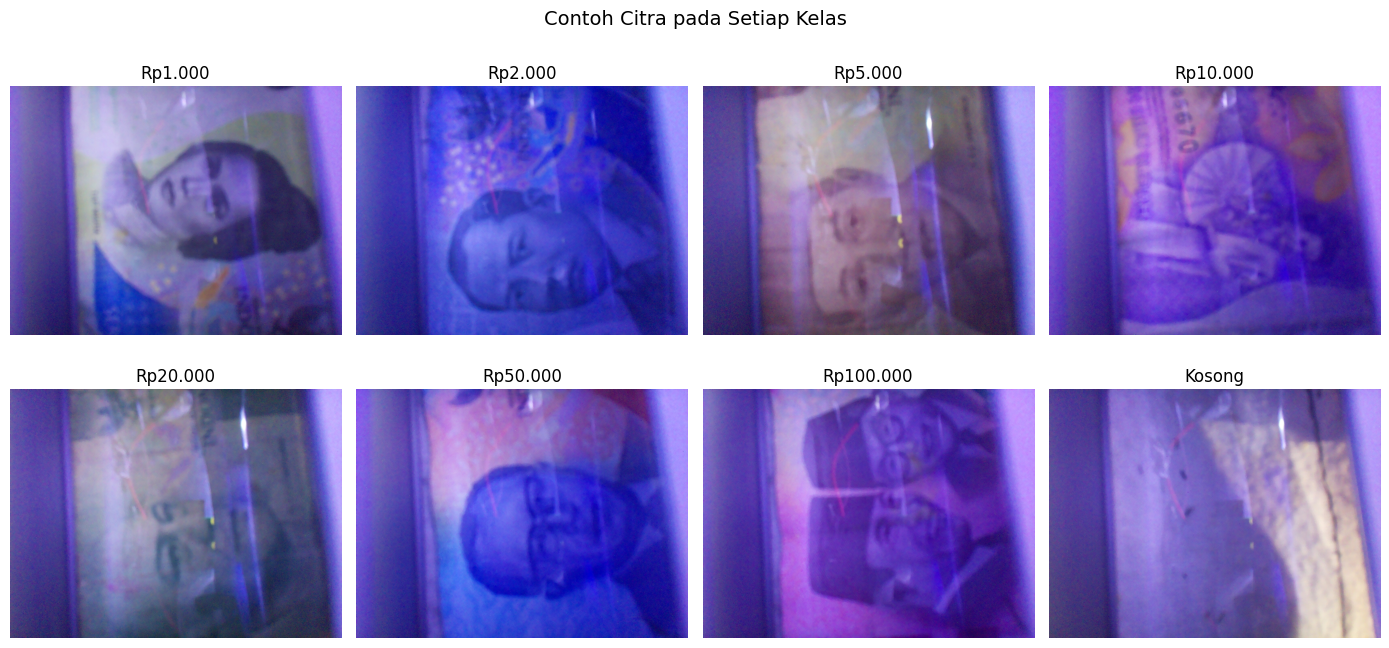

In [ ]:
plt.figure(figsize=(14, 7))

for index, class_name in enumerate(
    CLASS_NAMES,
    start=1,
):
    files = [
        p for p in (TRAIN_DIR / class_name).iterdir()
        if p.is_file() and p.suffix in VALID_EXTENSIONS
    ]

    if files:
        image = tf.keras.utils.load_img(files[0])

        plt.subplot(2, 4, index)
        plt.imshow(image)
        plt.title(DISPLAY_NAMES[class_name])
        plt.axis("off")

plt.suptitle(
    "Contoh Citra pada Setiap Kelas",
    fontsize=14,
)
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "02_contoh_citra_per_kelas.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 7. Load dataset TensorFlow

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Class weight membantu apabila kelas kosong memiliki
# jumlah gambar lebih sedikit daripada kelas nominal.
train_counts = {
    class_name: len(
        list((TRAIN_DIR / class_name).glob("*"))
    )
    for class_name in CLASS_NAMES
}

total_train = sum(train_counts.values())
num_classes = len(CLASS_NAMES)

class_weight = {
    index: total_train / (
        num_classes * train_counts[class_name]
    )
    for index, class_name in enumerate(CLASS_NAMES)
}

print("Class weight:")
for index, class_name in enumerate(CLASS_NAMES):
    print(
        DISPLAY_NAMES[class_name],
        ":",
        round(class_weight[index], 4),
    )


Found 1064 files belonging to 8 classes.
Found 228 files belonging to 8 classes.
Found 228 files belonging to 8 classes.
Class weight:
Rp1.000 : 0.95
Rp2.000 : 0.95
Rp5.000 : 0.95
Rp10.000 : 0.95
Rp20.000 : 0.95
Rp50.000 : 0.95
Rp100.000 : 0.95
Kosong : 1.5833


## 8. Buat model MobileNetV2 delapan kelas

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input,
)

NUM_CLASSES = len(CLASS_NAMES)

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.06, 0.06),
        layers.RandomZoom(0.08),
        layers.RandomContrast(0.15),
    ],
    name="data_augmentation",
)

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)

base_model.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image",
)
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification",
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification (Dense)          │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 9. Training tahap pertama

In [ ]:
STAGE1_MODEL_PATH = Path(
    "/content/best_mobilenetv2_8kelas_stage1.keras"
)

callbacks_stage1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        STAGE1_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
]

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_stage1,
    class_weight=class_weight,
)


Epoch 1/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.2498 - loss: 2.1564
Epoch 1: val_loss improved from None to 1.15125, saving model to /content/best_mobilenetv2_8kelas_stage1.keras

Epoch 1: finished saving model to /content/best_mobilenetv2_8kelas_stage1.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 25s 192ms/step - accuracy: 0.3618 - loss: 1.7626 - val_accuracy: 0.5526 - val_loss: 1.1513 - learning_rate: 0.0010
Epoch 2/30
66/67 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.6663 - loss: 0.9785
Epoch 2: val_loss improved from 1.15125 to 0.59909, saving model to /content/best_mobilenetv2_8kelas_stage1.keras

Epoch 2: finished saving model to /content/best_mobilenetv2_8kelas_stage1.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 12s 172ms/step - accuracy: 0.7077 - loss: 0.8835 - val_accuracy: 0.8289 - val_loss: 0.5991 - learning_rate: 0.0010
Epoch 3/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.7939 - loss: 0.6148
Epoch 3: val_loss improved from 0.59909 to 0.45067, saving model to /co

## 10. Fine-tuning

In [ ]:
RUN_FINE_TUNING = True

history_finetune = None
FINETUNED_MODEL_PATH = Path(
    "/content/best_mobilenetv2_8kelas_finetuned.keras"
)

if RUN_FINE_TUNING:
    base_model.trainable = True
    fine_tune_at = len(base_model.layers) - 30

    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-5
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

    callbacks_finetune = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=3,
            min_lr=1e-7,
            verbose=1,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            FINETUNED_MODEL_PATH,
            monitor="val_loss",
            save_best_only=True,
            verbose=1,
        ),
    ]

    history_finetune = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=25,
        callbacks=callbacks_finetune,
        class_weight=class_weight,
    )

    if FINETUNED_MODEL_PATH.exists():
        model = tf.keras.models.load_model(
            FINETUNED_MODEL_PATH
        )

else:
    model = tf.keras.models.load_model(
        STAGE1_MODEL_PATH
    )
    print("Fine-tuning dilewati.")


Epoch 1/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.7047 - loss: 0.9822
Epoch 1: val_loss improved from None to 0.05595, saving model to /content/best_mobilenetv2_8kelas_finetuned.keras

Epoch 1: finished saving model to /content/best_mobilenetv2_8kelas_finetuned.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 25s 198ms/step - accuracy: 0.7133 - loss: 0.9303 - val_accuracy: 0.9912 - val_loss: 0.0560 - learning_rate: 1.0000e-05
Epoch 2/25
66/67 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.7849 - loss: 0.6097
Epoch 2: val_loss improved from 0.05595 to 0.05224, saving model to /content/best_mobilenetv2_8kelas_finetuned.keras

Epoch 2: finished saving model to /content/best_mobilenetv2_8kelas_finetuned.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 11s 171ms/step - accuracy: 0.8083 - loss: 0.5640 - val_accuracy: 0.9912 - val_loss: 0.0522 - learning_rate: 1.0000e-05
Epoch 3/25
66/67 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.8722 - loss: 0.3909
Epoch 3: val_loss improved from 0.05224 to 0.04530,

## 11. Grafik akurasi dan loss

Dua grafik ini merupakan grafik utama yang perlu dimasukkan ke laporan untuk memperlihatkan konvergensi model dan indikasi overfitting.


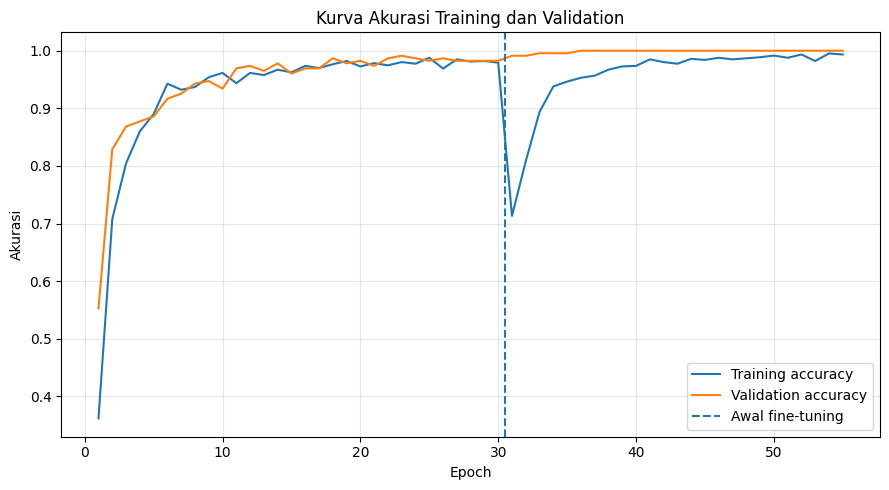

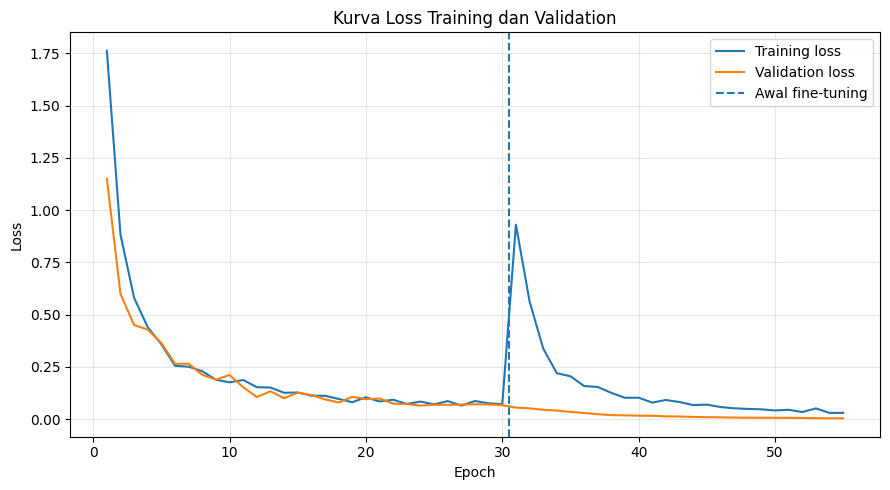

In [ ]:
def gabungkan_history(
    history_stage1,
    history_finetune=None,
):
    combined = {
        "accuracy": list(
            history_stage1.history["accuracy"]
        ),
        "val_accuracy": list(
            history_stage1.history["val_accuracy"]
        ),
        "loss": list(
            history_stage1.history["loss"]
        ),
        "val_loss": list(
            history_stage1.history["val_loss"]
        ),
    }

    stage1_length = len(
        history_stage1.history["accuracy"]
    )

    if history_finetune is not None:
        for metric in combined:
            combined[metric].extend(
                history_finetune.history[metric]
            )

    return combined, stage1_length


combined_history, stage1_length = gabungkan_history(
    history_stage1,
    history_finetune,
)

epochs = np.arange(
    1,
    len(combined_history["accuracy"]) + 1,
)

plt.figure(figsize=(9, 5))
plt.plot(
    epochs,
    combined_history["accuracy"],
    label="Training accuracy",
)
plt.plot(
    epochs,
    combined_history["val_accuracy"],
    label="Validation accuracy",
)

if history_finetune is not None:
    plt.axvline(
        stage1_length + 0.5,
        linestyle="--",
        label="Awal fine-tuning",
    )

plt.title("Kurva Akurasi Training dan Validation")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "03_kurva_akurasi.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    epochs,
    combined_history["loss"],
    label="Training loss",
)
plt.plot(
    epochs,
    combined_history["val_loss"],
    label="Validation loss",
)

if history_finetune is not None:
    plt.axvline(
        stage1_length + 0.5,
        linestyle="--",
        label="Awal fine-tuning",
    )

plt.title("Kurva Loss Training dan Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "04_kurva_loss.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 12. Evaluasi model pada data test

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1,
)

print(f"Test loss     : {test_loss:.6f}")
print(f"Test accuracy : {test_accuracy:.4%}")

y_true = []
y_pred = []
y_prob = []

for images, labels in test_ds:
    probabilities = model.predict(
        images,
        verbose=0,
    )

    y_true.extend(
        np.argmax(labels.numpy(), axis=1)
    )
    y_pred.extend(
        np.argmax(probabilities, axis=1)
    )
    y_prob.extend(probabilities)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(
    report_dict
).transpose()

display(report_df)

report_df.to_csv(
    REPORT_DIR / "classification_report_test.csv"
)


15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.9956 - loss: 0.0162
Test loss     : 0.016206
Test accuracy : 99.5614%


,precision,recall,f1-score,support
1000,1.000000,1.000000,1.000000,30.000000
2000,1.000000,1.000000,1.000000,30.000000
5000,1.000000,1.000000,1.000000,30.000000
10000,1.000000,0.966667,0.983051,30.000000
20000,1.000000,1.000000,1.000000,30.000000
50000,0.967742,1.000000,0.983607,30.000000
100000,1.000000,1.000000,1.000000,30.000000
kosong,1.000000,1.000000,1.000000,18.000000
accuracy,0.995614,0.995614,0.995614,0.995614
macro avg,0.995968,0.995833,0.995832,228.000000


## 13. Confusion matrix

Gunakan confusion matrix untuk menjelaskan kelas mana yang paling sering tertukar. Versi normalisasi membantu membandingkan kelas meskipun jumlah datanya berbeda.


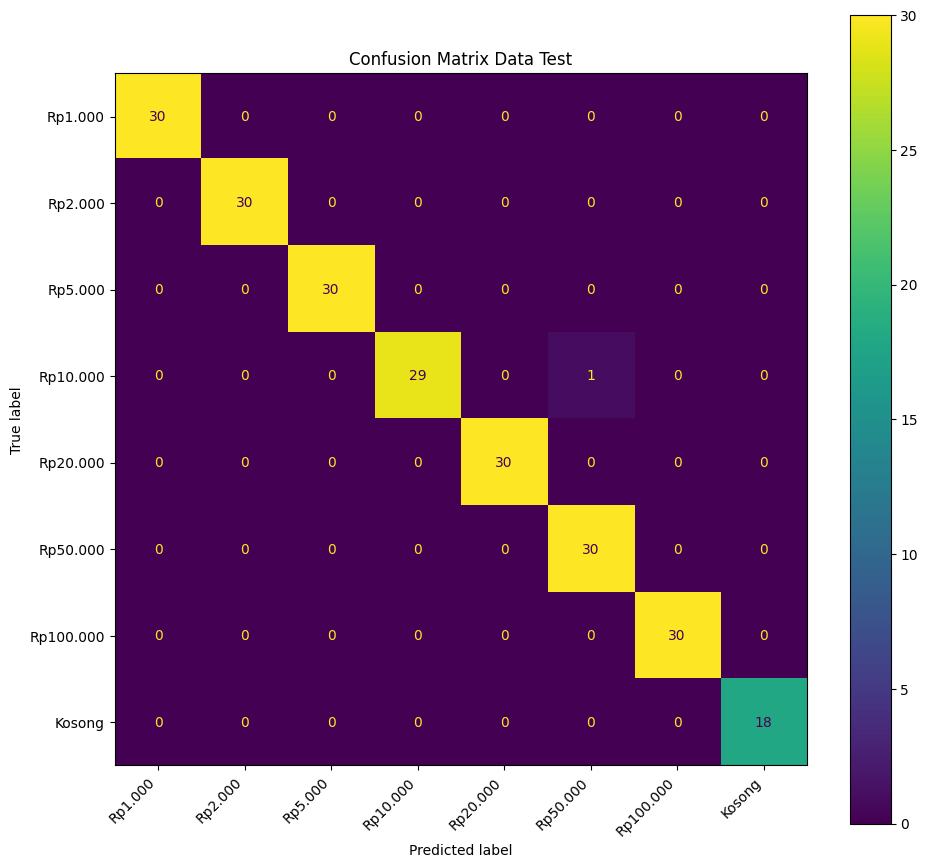

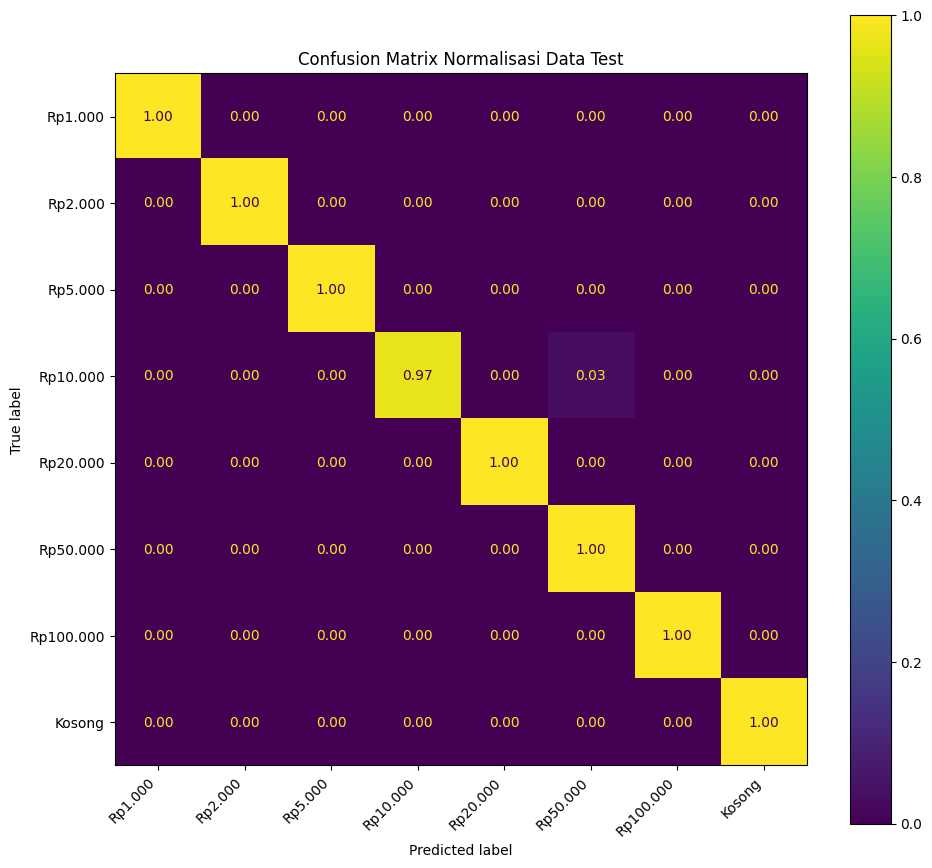

In [ ]:
display_labels = [
    DISPLAY_NAMES[c] for c in CLASS_NAMES
]

cm = confusion_matrix(
    y_true,
    y_pred,
)

plt.figure(figsize=(10, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels,
)
disp.plot(
    values_format="d",
    ax=plt.gca(),
)
plt.title("Confusion Matrix Data Test")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "05_confusion_matrix_test.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    normalize="true",
)

plt.figure(figsize=(10, 9))
disp_normalized = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=display_labels,
)
disp_normalized.plot(
    values_format=".2f",
    ax=plt.gca(),
)
plt.title("Confusion Matrix Normalisasi Data Test")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    REPORT_DIR
    / "06_confusion_matrix_normalisasi.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 14. Grafik precision, recall, dan F1-score per kelas

Grafik ini dapat dimasukkan ke laporan untuk menunjukkan performa setiap nominal dan kelas `kosong`, bukan hanya akurasi keseluruhan.


,kelas,precision,recall,f1-score
0,Rp1.000,1.000000,1.000000,1.000000
1,Rp2.000,1.000000,1.000000,1.000000
2,Rp5.000,1.000000,1.000000,1.000000
3,Rp10.000,1.000000,0.966667,0.983051
4,Rp20.000,1.000000,1.000000,1.000000
5,Rp50.000,0.967742,1.000000,0.983607
6,Rp100.000,1.000000,1.000000,1.000000
7,Kosong,1.000000,1.000000,1.000000


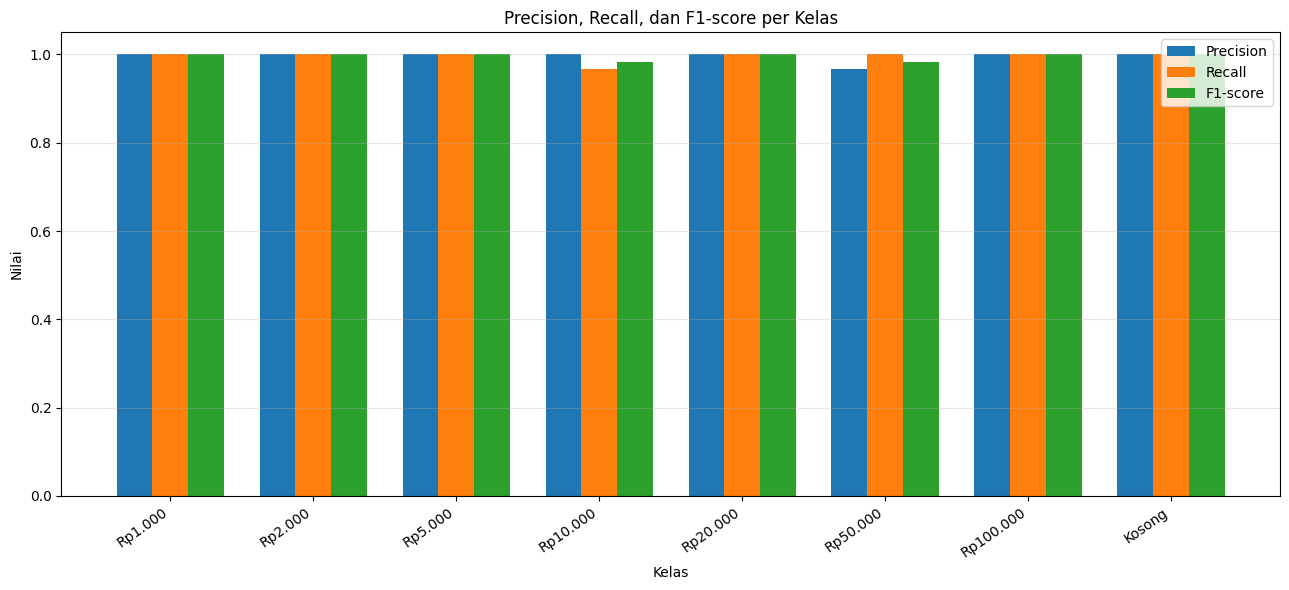

In [ ]:
metric_rows = []

for class_name in CLASS_NAMES:
    metric_rows.append({
        "kelas": DISPLAY_NAMES[class_name],
        "precision": report_dict[class_name]["precision"],
        "recall": report_dict[class_name]["recall"],
        "f1-score": report_dict[class_name]["f1-score"],
    })

metric_df = pd.DataFrame(metric_rows)
display(metric_df)

x = np.arange(len(metric_df))
bar_width = 0.25

plt.figure(figsize=(13, 6))
plt.bar(
    x - bar_width,
    metric_df["precision"],
    width=bar_width,
    label="Precision",
)
plt.bar(
    x,
    metric_df["recall"],
    width=bar_width,
    label="Recall",
)
plt.bar(
    x + bar_width,
    metric_df["f1-score"],
    width=bar_width,
    label="F1-score",
)

plt.title(
    "Precision, Recall, dan F1-score per Kelas"
)
plt.xlabel("Kelas")
plt.ylabel("Nilai")
plt.ylim(0, 1.05)
plt.xticks(
    x,
    metric_df["kelas"],
    rotation=35,
    ha="right",
)
plt.legend()
plt.grid(
    axis="y",
    alpha=0.3,
)
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "07_metric_per_kelas.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 15. Distribusi confidence prediksi

Grafik ini bersifat tambahan. Grafik berguna untuk menentukan ambang confidence dan melihat apakah prediksi salah masih memiliki confidence tinggi.


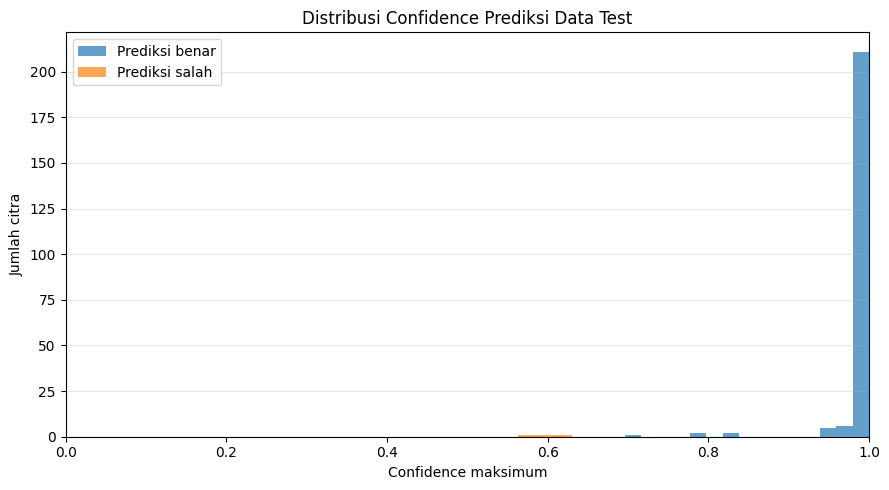

In [ ]:
prediction_confidence = np.max(
    y_prob,
    axis=1,
)

correct_mask = y_true == y_pred

plt.figure(figsize=(9, 5))

if np.any(correct_mask):
    plt.hist(
        prediction_confidence[correct_mask],
        bins=15,
        alpha=0.7,
        label="Prediksi benar",
    )

if np.any(~correct_mask):
    plt.hist(
        prediction_confidence[~correct_mask],
        bins=15,
        alpha=0.7,
        label="Prediksi salah",
    )

plt.title("Distribusi Confidence Prediksi Data Test")
plt.xlabel("Confidence maksimum")
plt.ylabel("Jumlah citra")
plt.xlim(0, 1)
plt.legend()
plt.grid(
    axis="y",
    alpha=0.3,
)
plt.tight_layout()
plt.savefig(
    REPORT_DIR
    / "08_distribusi_confidence.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 16. Contoh prediksi yang salah

Gambar ini dapat digunakan saat pembahasan untuk menunjukkan pola kesalahan model. Jika tidak terdapat kesalahan, notebook akan menampilkan pemberitahuan.


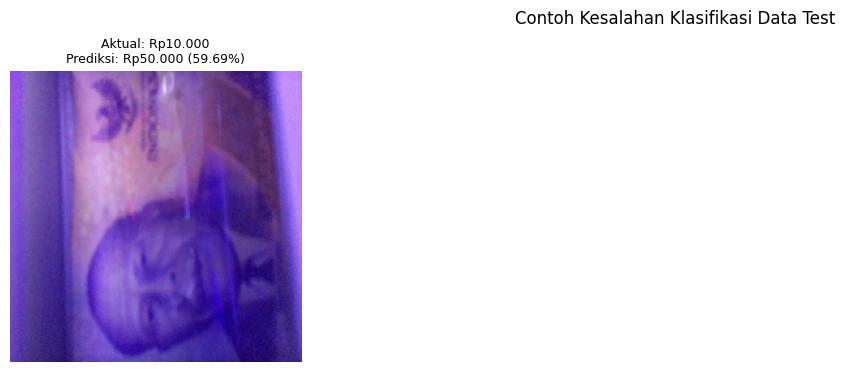

In [ ]:
test_file_paths = []

for class_name in CLASS_NAMES:
    class_files = sorted([
        p for p in (TEST_DIR / class_name).iterdir()
        if p.is_file() and p.suffix in VALID_EXTENSIONS
    ])
    test_file_paths.extend(class_files)

wrong_indices = np.where(y_true != y_pred)[0]

if len(wrong_indices) == 0:
    print(
        "Tidak ditemukan prediksi salah pada data test."
    )
else:
    selected_indices = wrong_indices[:12]

    plt.figure(figsize=(14, 10))

    for plot_index, data_index in enumerate(
        selected_indices,
        start=1,
    ):
        image_path = test_file_paths[data_index]
        image = tf.keras.utils.load_img(
            image_path,
            target_size=IMG_SIZE,
        )

        true_label = CLASS_NAMES[y_true[data_index]]
        pred_label = CLASS_NAMES[y_pred[data_index]]
        confidence = prediction_confidence[data_index]

        plt.subplot(3, 4, plot_index)
        plt.imshow(image)
        plt.title(
            "Aktual: "
            f"{DISPLAY_NAMES[true_label]}\n"
            "Prediksi: "
            f"{DISPLAY_NAMES[pred_label]} "
            f"({confidence:.2%})",
            fontsize=9,
        )
        plt.axis("off")

    plt.suptitle(
        "Contoh Kesalahan Klasifikasi Data Test"
    )
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR
        / "09_contoh_prediksi_salah.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


## 17. Simpan model Keras, TFLite, labels, grafik, dan tabel

In [ ]:
OUTPUT_DIR = Path("/content/output_model_8kelas")

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

KERAS_PATH = (
    OUTPUT_DIR
    / "mobilenetv2_uang_rupiah_8kelas.keras"
)
TFLITE_PATH = (
    OUTPUT_DIR
    / "mobilenetv2_uang_rupiah_8kelas.tflite"
)
LABELS_PATH = OUTPUT_DIR / "labels.txt"

model.save(KERAS_PATH)

with open(
    LABELS_PATH,
    "w",
    encoding="utf-8",
) as file:
    for label in CLASS_NAMES:
        file.write(label + "\n")

converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)
converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]
tflite_model = converter.convert()

with open(TFLITE_PATH, "wb") as file:
    file.write(tflite_model)

# Salin grafik dan tabel laporan ke output.
REPORT_OUTPUT_DIR = OUTPUT_DIR / "report_figures"
shutil.copytree(
    REPORT_DIR,
    REPORT_OUTPUT_DIR,
    dirs_exist_ok=True,
)

print("Keras :", KERAS_PATH)
print("TFLite:", TFLITE_PATH)
print("Labels:", LABELS_PATH)
print(
    "Ukuran TFLite:",
    round(
        TFLITE_PATH.stat().st_size / 1024,
        2,
    ),
    "KB",
)
print(
    "Grafik laporan:",
    REPORT_OUTPUT_DIR,
)


Saved artifact at '/tmp/tmp_sbh3x1m'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  135969759977232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135969759971856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135969759973008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135969759984528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135969759984912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135966997479888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135966997480848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135966997479504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135966997480464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135966997481424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135966997480656

## 18. Tes prediksi satu gambar

Sample: /content/dataset_split/test/1000/1000_0190_1784029939.jpg


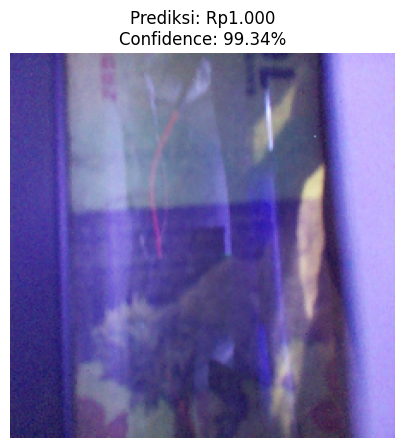

   Rp1.000: 0.9934
   Rp2.000: 0.0002
   Rp5.000: 0.0000
  Rp10.000: 0.0000
  Rp20.000: 0.0021
  Rp50.000: 0.0041
 Rp100.000: 0.0000
    Kosong: 0.0001


In [ ]:
def predict_image(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE,
    )

    array = tf.keras.utils.img_to_array(image)
    array_batch = np.expand_dims(
        array,
        axis=0,
    )

    prediction = model.predict(
        array_batch,
        verbose=0,
    )[0]

    pred_index = int(np.argmax(prediction))
    pred_label = CLASS_NAMES[pred_index]
    confidence = float(prediction[pred_index])

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        "Prediksi: "
        f"{DISPLAY_NAMES[pred_label]}\n"
        f"Confidence: {confidence:.2%}"
    )
    plt.show()

    for class_name, probability in zip(
        CLASS_NAMES,
        prediction,
    ):
        print(
            f"{DISPLAY_NAMES[class_name]:>10}: "
            f"{probability:.4f}"
        )


sample_path = None

for class_name in CLASS_NAMES:
    files = [
        p for p in (TEST_DIR / class_name).iterdir()
        if p.is_file() and p.suffix in VALID_EXTENSIONS
    ]

    if files:
        sample_path = files[0]
        break

print("Sample:", sample_path)

if sample_path is not None:
    predict_image(sample_path)


## 19. ZIP dan download seluruh output

In [ ]:
ZIP_PATH = (
    "/content/output_model_uang_rupiah_8kelas.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED,
) as archive:
    for file_path in OUTPUT_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                file_path.relative_to(OUTPUT_DIR),
            )

print("ZIP output:", ZIP_PATH)

from google.colab import files
files.download(ZIP_PATH)


ZIP output: /content/output_model_uang_rupiah_8kelas.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Grafik utama untuk laporan

Grafik yang paling penting dimasukkan ke BAB IV:

1. **Distribusi dataset per kelas** — menjelaskan komposisi data.
2. **Contoh citra setiap kelas** — menunjukkan karakteristik data nominal dan area kosong.
3. **Kurva akurasi training dan validation** — menunjukkan perkembangan akurasi.
4. **Kurva loss training dan validation** — membantu mendeteksi overfitting.
5. **Confusion matrix data test** — menunjukkan pola salah klasifikasi.
6. **Grafik precision, recall, dan F1-score per kelas** — menunjukkan performa setiap nominal serta kelas kosong.

Grafik confidence dan contoh prediksi salah dapat digunakan sebagai grafik tambahan pada bagian pembahasan atau lampiran.
